# Lab 6 : Covariance, Correlation & Principal Component Analysis
**Lakshay** : AP24110010677 : B.Tech CSE (AI/ML)

**Question 1** : Compute covariance and correlation between a pair of attributes; compute the covariance matrix and the correlation matrix.

**Question 2** : Principal Component Analysis (PCA).

**Dataset** : a **randomly generated** student dataset (100 students, 5 numeric attributes + a Pass/Fail label), created with NumPy using random seed **77** (last two digits of roll number).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 77                     # last two digits of roll number
np.random.seed(SEED)
pd.set_option("display.precision", 4)

## Creating the random dataset
Each student gets 5 attributes. Some are built to depend on others (with random noise added), so the dataset has positive, negative and near-zero relationships to study:

| Attribute | How it is generated |
|---|---|
| `study_hours` | random, uniform 1 to 10 hours/day |
| `attendance` | random, ~ 75% ± 10 (independent of study hours) |
| `screen_time` | goes **down** as study hours go up, + noise |
| `sleep_hours` | random, ~ 7 ± 1 (independent of everything) |
| `marks` | goes **up** with study hours and attendance, **down** with screen time, + noise |

`result` = 1 (Pass) if marks ≥ 50, else 0 (Fail).

In [2]:
n = 100
study_hours = np.random.uniform(1, 10, n)
attendance  = np.clip(np.random.normal(75, 10, n), 40, 100)
screen_time = np.clip(9 - 0.6 * study_hours + np.random.normal(0, 1, n), 0.5, None)
sleep_hours = np.random.normal(7, 1, n)
marks = np.clip(5 * study_hours + 0.4 * attendance - 2 * screen_time + np.random.normal(0, 6, n), 0, 100)

df = pd.DataFrame({
    "study_hours": study_hours.round(1),
    "attendance":  attendance.round(1),
    "screen_time": screen_time.round(1),
    "sleep_hours": sleep_hours.round(1),
    "marks":       marks.round(1),
})
df["result"] = (df["marks"] >= 50).astype(int)

print("Shape :", df.shape)
df.head(10)

Shape : (100, 6)


,study_hours,attendance,screen_time,sleep_hours,marks,result
0,9.3,84.6,4.2,6.6,66.6,1
1,6.8,76.5,3.7,7.7,60.1,1
2,7.8,85.6,4.8,6.2,67.3,1
3,2.3,67.7,8.2,6.4,28.6,0
4,1.8,68.1,6.8,7.3,19.9,0
5,8.1,65.6,4.2,8.0,55.2,1
6,3.9,65.7,6.3,6.5,26.4,0
7,5.9,66.6,4.4,7.2,52.9,1
8,3.2,75.3,6.4,9.1,40.2,0
9,5.9,73.7,6.2,5.8,46.4,0


In [3]:
df.describe()

,study_hours,attendance,screen_time,sleep_hours,marks,result
count,100.0000,100.0000,100.0000,100.0000,100.0000,100.000
mean,5.3170,75.6230,5.5610,7.0020,45.7620,0.420
std,2.6062,10.0974,1.8369,1.0372,18.0147,0.496
min,1.1000,54.5000,1.7000,4.6000,10.1000,0.000
25%,3.3000,69.0250,4.1000,6.3000,31.4750,0.000
50%,4.9500,75.5000,5.5500,7.0000,44.4000,0.000
75%,7.7000,82.0000,7.1250,7.7000,59.7250,1.000
max,10.0000,100.0000,9.5000,9.5000,84.3000,1.000


In [4]:
print("Pass / Fail count :")
print(df["result"].value_counts().rename({1: "Pass", 0: "Fail"}))

Pass / Fail count :
result
Fail    58
Pass    42
Name: count, dtype: int64


---
# Question 1 : Covariance & Correlation

### Theory
**Covariance** shows the *direction* in which two attributes move together.

$$\text{Cov}(X,Y) = \frac{1}{n-1}\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})$$

* Cov > 0 : both increase together  ·  Cov < 0 : one increases while the other decreases  ·  Cov ≈ 0 : no linear relationship
* Its value depends on the units of X and Y, so it shows direction but **not strength**.

**Correlation (Pearson)** standardises covariance by both standard deviations, so it is unit-free and always lies in **[-1, +1]**.

$$r_{XY} = \frac{\text{Cov}(X,Y)}{\sigma_X\,\sigma_Y}$$

**Spearman's rank correlation** is Pearson correlation applied to the *ranks* of the values; it captures any monotonic relationship and is robust to outliers.

**Covariance matrix** (d × d) : entry (i, j) = Cov(Xᵢ, Xⱼ); the diagonal holds the variances; it is symmetric.
**Correlation matrix** (d × d) : entry (i, j) = r(Xᵢ, Xⱼ); the diagonal is always 1; it is symmetric.

| | Covariance | Correlation |
|---|---|---|
| Range | −∞ to +∞ | −1 to +1 |
| Units | depends on the data's units | unit-free |
| Tells | direction only | direction **and** strength |

### Part A : Small worked example (by hand)
Hours studied (X) vs exam score (Y) for 5 students.

In [5]:
X = np.array([2, 4, 6, 8, 10])
Y = np.array([50, 60, 65, 80, 95])
m = len(X)

dx, dy = X - X.mean(), Y - Y.mean()
table = pd.DataFrame({"x": X, "y": Y, "x - x̄": dx, "y - ȳ": dy, "(x - x̄)(y - ȳ)": dx * dy})
print(table.to_string(index=False))
print(f"\nx̄ = {X.mean()},  ȳ = {Y.mean()},  Σ(x - x̄)(y - ȳ) = {np.sum(dx * dy)}")

 x  y  x - x̄  y - ȳ  (x - x̄)(y - ȳ)
 2 50    -4.0  -20.0             80.0
 4 60    -2.0  -10.0             20.0
 6 65     0.0   -5.0             -0.0
 8 80     2.0   10.0             20.0
10 95     4.0   25.0            100.0

x̄ = 6.0,  ȳ = 70.0,  Σ(x - x̄)(y - ȳ) = 220.0


In [6]:
cov_xy = np.sum(dx * dy) / (m - 1)
r_xy = cov_xy / (np.std(X, ddof=1) * np.std(Y, ddof=1))

print(f"Covariance  (manual) = {cov_xy:.4f}   |  np.cov      = {np.cov(X, Y)[0, 1]:.4f}")
print(f"Correlation (manual) = {r_xy:.4f}   |  np.corrcoef = {np.corrcoef(X, Y)[0, 1]:.4f}")

Covariance  (manual) = 55.0000   |  np.cov      = 55.0000
Correlation (manual) = 0.9839   |  np.corrcoef = 0.9839


Both are positive and r ≈ 0.98 : more study hours goes with higher scores, and the relationship is almost perfectly linear.

### Part B1 : Covariance & correlation between a pair of attributes (random dataset)
Three pairs, chosen to show all three cases : positive, negative and no relationship.

In [7]:
def cov_manual(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    return np.sum((a - a.mean()) * (b - b.mean())) / (len(a) - 1)

def corr_manual(a, b):
    return cov_manual(a, b) / (np.std(a, ddof=1) * np.std(b, ddof=1))

pairs = [("study_hours", "marks"), ("study_hours", "screen_time"), ("sleep_hours", "marks")]
rows = []
for a, b in pairs:
    rows.append({"pair": f"{a} vs {b}",
                 "cov (manual)": cov_manual(df[a], df[b]),
                 "cov (pandas)": df[a].cov(df[b]),
                 "pearson r (manual)": corr_manual(df[a], df[b]),
                 "pearson r (pandas)": df[a].corr(df[b]),
                 "spearman ρ": df[a].corr(df[b], method="spearman")})
pd.DataFrame(rows).set_index("pair")

,cov (manual),cov (pandas),pearson r (manual),pearson r (pandas),spearman ρ
pair,,,,,
study_hours vs marks,42.9173,42.9173,0.9141,0.9141,0.9114
study_hours vs screen_time,-4.1258,-4.1258,-0.8618,-0.8618,-0.8772
sleep_hours vs marks,-0.8312,-0.8312,-0.0445,-0.0445,-0.0137


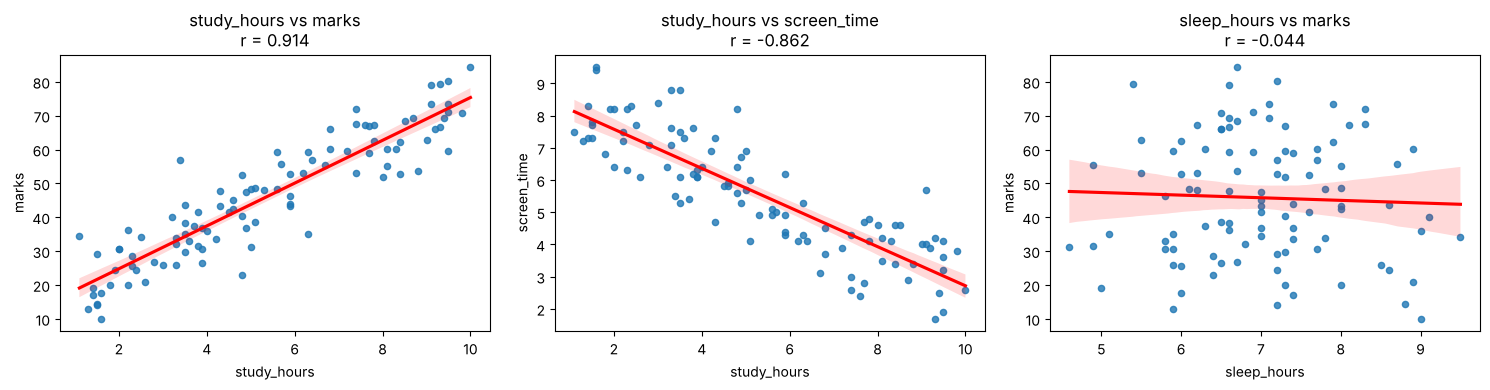

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (a, b) in zip(axes, pairs):
    sns.regplot(data=df, x=a, y=b, ax=ax, scatter_kws={"s": 20}, line_kws={"color": "red"})
    ax.set_title(f"{a} vs {b}\nr = {df[a].corr(df[b]):.3f}")
plt.tight_layout()
plt.show()

**Observation**
* study_hours vs marks : strong **positive** correlation : studying more → higher marks.
* study_hours vs screen_time : strong **negative** correlation : studying more → less screen time.
* sleep_hours vs marks : correlation close to **0** : no linear relationship (sleep was generated independently).
* Manual and pandas values match exactly.

### Part B2 : Covariance matrix

In [9]:
num = df.drop(columns="result")

# manual : (1 / (n-1)) · Xcᵀ Xc, where Xc = mean-centred data
Xc = num.values - num.values.mean(axis=0)
cov_matrix_manual = (Xc.T @ Xc) / (len(num) - 1)

cov_matrix = num.cov()          # pandas  (same as np.cov(num.values, rowvar=False))
print("Manual equals pandas :", np.allclose(cov_matrix_manual, cov_matrix.values))
cov_matrix

Manual equals pandas : True


,study_hours,attendance,screen_time,sleep_hours,marks
study_hours,6.7921,4.0714,-4.1258,-0.3545,42.9173
attendance,4.0714,101.9573,-2.5554,1.1961,60.6605
screen_time,-4.1258,-2.5554,3.3741,0.1813,-27.5021
sleep_hours,-0.3545,1.1961,0.1813,1.0758,-0.8312
marks,42.9173,60.6605,-27.5021,-0.8312,324.5309


### Part B3 : Correlation matrix

In [10]:
# manual : divide each covariance by the product of the two standard deviations
std = np.sqrt(np.diag(cov_matrix_manual))
corr_matrix_manual = cov_matrix_manual / np.outer(std, std)

corr_matrix = num.corr()        # pandas (Pearson)  (same as np.corrcoef(num.values, rowvar=False))
print("Manual equals pandas :", np.allclose(corr_matrix_manual, corr_matrix.values))
corr_matrix

Manual equals pandas : True


,study_hours,attendance,screen_time,sleep_hours,marks
study_hours,1.0000,0.1547,-0.8618,-0.1311,0.9141
attendance,0.1547,1.0000,-0.1378,0.1142,0.3335
screen_time,-0.8618,-0.1378,1.0000,0.0952,-0.8311
sleep_hours,-0.1311,0.1142,0.0952,1.0000,-0.0445
marks,0.9141,0.3335,-0.8311,-0.0445,1.0000


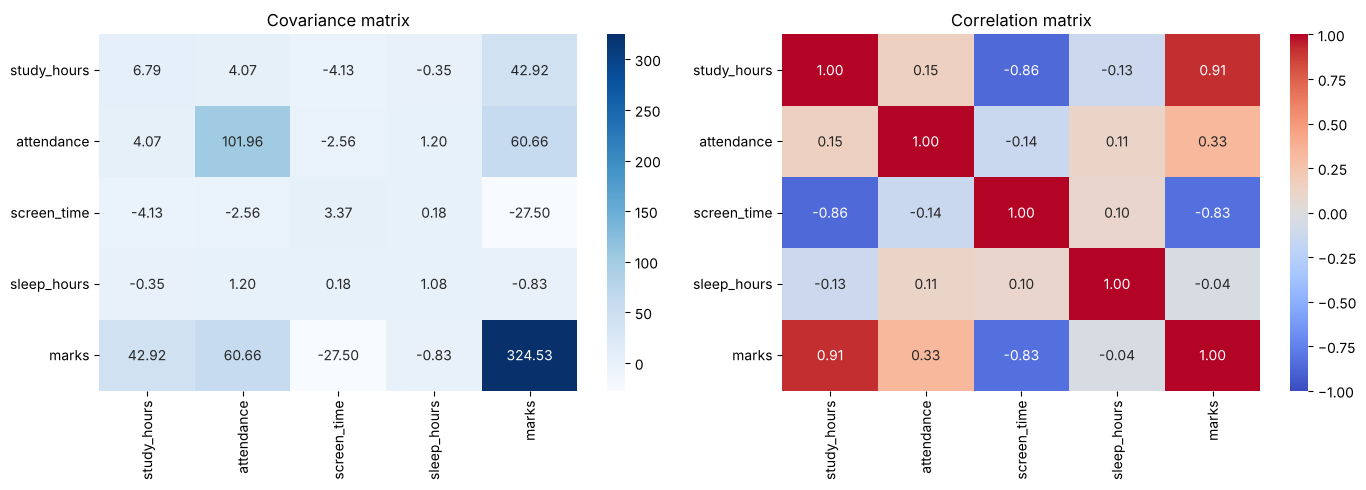

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(cov_matrix, annot=True, fmt=".2f", cmap="Blues", ax=axes[0])
axes[0].set_title("Covariance matrix")
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Correlation matrix")
plt.tight_layout()
plt.show()

### Result (Question 1)
* Covariance and correlation for pairs of attributes, and the full covariance and correlation matrices, were computed manually and with NumPy/pandas; both give identical values.
* The **covariance matrix** values depend on units (attendance and marks have large variances, so their covariances look large), which makes them hard to compare.
* The **correlation matrix** is unit-free : marks is strongly positive with study_hours, negative with screen_time, and ≈ 0 with sleep_hours, exactly matching how the data was generated.
* Attributes that are strongly correlated carry overlapping information; PCA (Question 2) uses this to reduce dimensions.

---
# Question 2 : Principal Component Analysis (PCA)
**Aim** : Reduce the 5 numeric attributes of the random student dataset to 2 principal components, implementing PCA step by step from scratch and verifying with scikit-learn.

### Theory
PCA finds new axes (**principal components**) along which the data varies the most. The components are orthogonal and uncorrelated, ordered by how much variance they capture, so keeping only the first *k* reduces the dimensions while losing as little information as possible.

**Steps**
1. **Standardise** each feature (mean 0, std 1) so features with large units do not dominate.
2. Compute the **covariance matrix** C of the standardised data.
3. Find the **eigenvalues and eigenvectors** of C (C·v = λ·v).
4. **Sort** by eigenvalue, largest first : eigenvector = direction of a PC, eigenvalue = variance along it.
5. **Explained variance ratio** of PCᵢ = λᵢ / Σλ; choose k.
6. **Project** : Z = X · W, where W holds the top-k eigenvectors as columns.

In [12]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

features = ["study_hours", "attendance", "screen_time", "sleep_hours", "marks"]
X = df[features].values
y = df["result"].values
print("X shape :", X.shape)

X shape : (100, 5)


### Step 1 : Standardise the data

In [13]:
X_std = (X - X.mean(axis=0)) / X.std(axis=0)

print("Means after standardising :", X_std.mean(axis=0).round(4))
print("Stds  after standardising :", X_std.std(axis=0).round(4))

Means after standardising : [-0. -0.  0. -0. -0.]
Stds  after standardising : [1. 1. 1. 1. 1.]


### Step 2 : Covariance matrix of the standardised data

In [14]:
cov = (X_std.T @ X_std) / (X_std.shape[0] - 1)
pd.DataFrame(cov, index=features, columns=features)

,study_hours,attendance,screen_time,sleep_hours,marks
study_hours,1.0101,0.1563,-0.8705,-0.1325,0.9233
attendance,0.1563,1.0101,-0.1392,0.1154,0.3368
screen_time,-0.8705,-0.1392,1.0101,0.0961,-0.8395
sleep_hours,-0.1325,0.1154,0.0961,1.0101,-0.0449
marks,0.9233,0.3368,-0.8395,-0.0449,1.0101


### Step 3 & 4 : Eigenvalues and eigenvectors (sorted)

In [15]:
eig_vals, eig_vecs = np.linalg.eigh(cov)      # eigh : for symmetric matrices

order = np.argsort(eig_vals)[::-1]             # largest → smallest
eig_vals, eig_vecs = eig_vals[order], eig_vecs[:, order]

pcs = [f"PC{i+1}" for i in range(len(features))]
print("Eigenvalues :", eig_vals.round(4))
pd.DataFrame(eig_vecs, index=features, columns=pcs)

Eigenvalues : [2.849  1.1359 0.8309 0.1689 0.0657]


,PC1,PC2,PC3,PC4,PC5
study_hours,-0.5704,-0.1040,-0.1282,0.3759,-0.7114
attendance,-0.1908,0.6456,0.7190,-0.1129,-0.1305
screen_time,0.5505,0.0939,0.1777,0.8080,-0.0602
sleep_hours,0.0719,0.7472,-0.6591,0.0058,-0.0451
marks,-0.5744,0.0723,-0.0238,0.4393,0.6865


### Step 5 : Explained variance and choosing k

In [16]:
explained = eig_vals / eig_vals.sum()
cumulative = np.cumsum(explained)

pd.DataFrame({"Eigenvalue": eig_vals,
              "Explained variance %": explained * 100,
              "Cumulative %": cumulative * 100}, index=pcs)

,Eigenvalue,Explained variance %,Cumulative %
PC1,2.8490,56.4108,56.4108
PC2,1.1359,22.4915,78.9023
PC3,0.8309,16.4526,95.3549
PC4,0.1689,3.3435,98.6984
PC5,0.0657,1.3016,100.0000


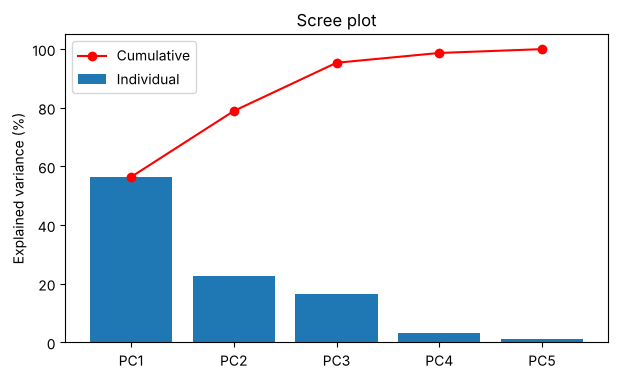

In [17]:
plt.figure(figsize=(7, 4))
plt.bar(pcs, explained * 100, label="Individual")
plt.plot(pcs, cumulative * 100, "o-", color="red", label="Cumulative")
plt.ylabel("Explained variance (%)")
plt.title("Scree plot")
plt.legend()
plt.show()

In [18]:
k = 2
print(f"PC1 + PC2 together explain {cumulative[k-1]*100:.2f}% of the total variance")

PC1 + PC2 together explain 78.90% of the total variance


### Step 6 : Project the data onto the top 2 components

In [19]:
W = eig_vecs[:, :k]              # 5 × 2 projection matrix
Z = X_std @ W                    # 100 × 2

pca_df = pd.DataFrame(Z, columns=["PC1", "PC2"])
pca_df["result"] = np.where(y == 1, "Pass", "Fail")
pca_df.head()

,PC1,PC2,result
0,-2.1525,0.1402,Pass
1,-1.3143,0.4645,Pass
2,-1.7111,0.0086,Pass
3,2.1171,-0.7577,Fail
4,2.1393,-0.1673,Fail


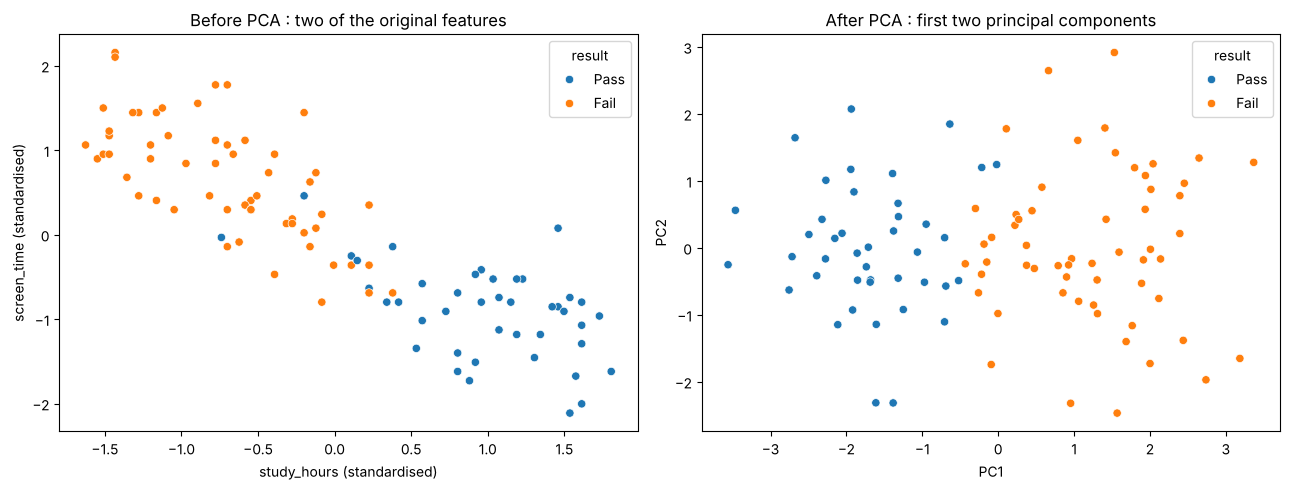

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(x=X_std[:, 0], y=X_std[:, 2], hue=pca_df["result"], ax=axes[0])
axes[0].set_xlabel("study_hours (standardised)"); axes[0].set_ylabel("screen_time (standardised)")
axes[0].set_title("Before PCA : two of the original features")
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="result", ax=axes[1])
axes[1].set_title("After PCA : first two principal components")
plt.tight_layout()
plt.show()

### Interpreting the components (loadings)

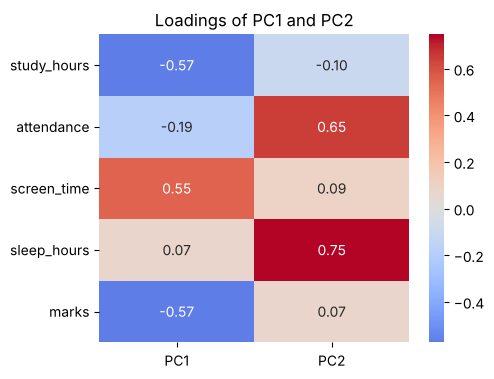

In [21]:
loadings = pd.DataFrame(W, index=features, columns=["PC1", "PC2"])
plt.figure(figsize=(5, 4))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Loadings of PC1 and PC2")
plt.show()

* **PC1** has large weights on study_hours, marks and (with opposite sign) screen_time : it is an "academic effort" axis, and Pass and Fail students separate along it.
* **PC2** is dominated by the independent attributes (attendance / sleep_hours), which did not fit into PC1.

### Verification with scikit-learn
Eigenvectors are unique only up to sign, so sklearn's components may be flipped (×-1); we compare absolute values.

In [22]:
X_sk = StandardScaler().fit_transform(X)
pca = PCA(n_components=2, random_state=SEED)
Z_sk = pca.fit_transform(X_sk)

print("sklearn explained variance ratio :", pca.explained_variance_ratio_.round(4))
print("manual  explained variance ratio :", explained[:2].round(4))
print("Projections match (up to sign)   :", np.allclose(np.abs(Z), np.abs(Z_sk)))

sklearn explained variance ratio : [0.5641 0.2249]
manual  explained variance ratio : [0.5641 0.2249]
Projections match (up to sign)   : True


### Using the principal components for classification
A logistic-regression model predicts Pass/Fail using only the 2 principal components instead of all 5 features.

Accuracy with all 4 features : 0.867
Accuracy with 2 PCs          : 0.833


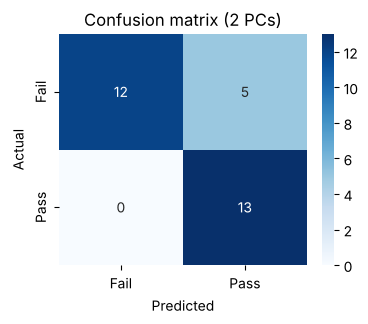

In [23]:
features_no_marks = ["study_hours", "attendance", "screen_time", "sleep_hours"]   # marks would leak the label
X2 = StandardScaler().fit_transform(df[features_no_marks])
X_tr, X_te, y_tr, y_te = train_test_split(X2, y, test_size=0.3, random_state=SEED, stratify=y)

pca2 = PCA(n_components=2, random_state=SEED).fit(X_tr)
clf_pca = LogisticRegression().fit(pca2.transform(X_tr), y_tr)
clf_all = LogisticRegression().fit(X_tr, y_tr)

acc_pca = accuracy_score(y_te, clf_pca.predict(pca2.transform(X_te)))
acc_all = accuracy_score(y_te, clf_all.predict(X_te))
print(f"Accuracy with all 4 features : {acc_all:.3f}")
print(f"Accuracy with 2 PCs          : {acc_pca:.3f}")

cm = confusion_matrix(y_te, clf_pca.predict(pca2.transform(X_te)))
plt.figure(figsize=(4, 3))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Fail", "Pass"], yticklabels=["Fail", "Pass"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion matrix (2 PCs)")
plt.show()

`marks` is left out here because `result` is calculated directly from marks; including it would let the model "cheat".

### Result (Question 2)
* PCA was implemented from scratch (standardise → covariance matrix → eigen-decomposition → sort → project) and matched scikit-learn's output exactly (up to sign).
* The first two principal components keep most of the variance of the 5 original attributes, so the data can be shown and used in 2D.
* PC1 combines the correlated attributes (study hours, screen time, marks) found in Question 1, which shows how correlation drives PCA.
* A classifier trained on just 2 PCs performs about as well as one using all the features, so PCA reduced the dimensions without losing useful information.